# KNN Regression

In [3]:
import pandas as pd

In [4]:
df = pd.read_csv("housing_price_dataset.csv")
df.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
0,2126,4,1,Rural,1969,215355.283618
1,2459,3,2,Rural,1980,195014.221626
2,1860,2,1,Suburb,1970,306891.012076
3,2294,2,1,Urban,1996,206786.787153
4,2130,5,2,Suburb,2001,272436.239065


In [5]:
print(df.shape)

(50000, 6)


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SquareFeet    50000 non-null  int64  
 1   Bedrooms      50000 non-null  int64  
 2   Bathrooms     50000 non-null  int64  
 3   Neighborhood  50000 non-null  object 
 4   YearBuilt     50000 non-null  int64  
 5   Price         50000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 2.3+ MB
None


In [7]:
print(df.describe())

         SquareFeet      Bedrooms     Bathrooms     YearBuilt          Price
count  50000.000000  50000.000000  50000.000000  50000.000000   50000.000000
mean    2006.374680      3.498700      1.995420   1985.404420  224827.325151
std      575.513241      1.116326      0.815851     20.719377   76141.842966
min     1000.000000      2.000000      1.000000   1950.000000  -36588.165397
25%     1513.000000      3.000000      1.000000   1967.000000  169955.860225
50%     2007.000000      3.000000      2.000000   1985.000000  225052.141166
75%     2506.000000      4.000000      3.000000   2003.000000  279373.630052
max     2999.000000      5.000000      3.000000   2021.000000  492195.259972


In [8]:
print(df.isnull().sum())

SquareFeet      0
Bedrooms        0
Bathrooms       0
Neighborhood    0
YearBuilt       0
Price           0
dtype: int64


In [9]:
X = df.drop("Price", axis = 1)
X

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt
0,2126,4,1,Rural,1969
1,2459,3,2,Rural,1980
2,1860,2,1,Suburb,1970
3,2294,2,1,Urban,1996
4,2130,5,2,Suburb,2001
...,...,...,...,...,...
49995,1282,5,3,Rural,1975
49996,2854,2,2,Suburb,1988
49997,2979,5,3,Suburb,1962
49998,2596,5,2,Rural,1984


In [10]:
y = df["Price"]
y

0        215355.283618
1        195014.221626
2        306891.012076
3        206786.787153
4        272436.239065
             ...      
49995    100080.865895
49996    374507.656727
49997    384110.555590
49998    380512.685957
49999    221618.583218
Name: Price, Length: 50000, dtype: float64

In [11]:
X = pd.get_dummies(
    X,
    columns = ["Neighborhood"],
    dtype = int
)

print(X.head())

   SquareFeet  Bedrooms  Bathrooms  YearBuilt  Neighborhood_Rural  \
0        2126         4          1       1969                   1   
1        2459         3          2       1980                   1   
2        1860         2          1       1970                   0   
3        2294         2          1       1996                   0   
4        2130         5          2       2001                   0   

   Neighborhood_Suburb  Neighborhood_Urban  
0                    0                   0  
1                    0                   0  
2                    1                   0  
3                    0                   1  
4                    1                   0  


In [12]:
from sklearn.model_selection import train_test_split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

In [14]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
from sklearn.neighbors import KNeighborsRegressor

In [16]:
knn = KNeighborsRegressor()
knn

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [17]:
knn = KNeighborsRegressor(n_neighbors = 5)
knn

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [18]:
knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [19]:
y_pred = knn.predict(X_test_scaled)
print(y_pred[:10])

[240980.59993777 151296.88292096 252281.04854515 249310.83013994
 281856.52122967 182341.18469691 310692.06273363 197676.47014418
 321594.92677566 237941.8192804 ]


In [20]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))

    Actual Price  Predicted Price
0  170835.035713    240980.599938
1  126913.469998    151296.882921
2  246611.883092    252281.048545
3  244250.462969    249310.830140
4  271127.650112    281856.521230
5  189289.951199    182341.184697
6  343510.576500    310692.062734
7  203461.591080    197676.470144
8  285903.247682    321594.926776
9  224868.958375    237941.819280


In [21]:
new_house = pd.DataFrame({
    "SquareFeet" : [2000],
    "Bedrooms" : [3],
    "Bathrooms": [2],
    "Neighborhood": ["Suburb"],
    "YearBuilt": [1990]
})
print(new_house)

   SquareFeet  Bedrooms  Bathrooms Neighborhood  YearBuilt
0        2000         3          2       Suburb       1990


In [22]:
new_house = pd.get_dummies(
    new_house,
    columns = ["Neighborhood"],
    dtype = int
)

print(new_house)

   SquareFeet  Bedrooms  Bathrooms  YearBuilt  Neighborhood_Suburb
0        2000         3          2       1990                    1


In [23]:
X_train

,SquareFeet,Bedrooms,Bathrooms,YearBuilt,Neighborhood_Rural,Neighborhood_Suburb,Neighborhood_Urban
39087,2498,2,3,2021,1,0,0
30893,2380,5,3,1977,0,0,1
45278,2274,5,2,1957,0,0,1
16398,2215,5,1,1977,0,1,0
13653,2078,2,3,1962,0,1,0
...,...,...,...,...,...,...,...
11284,2166,5,3,1996,0,1,0
44732,2463,4,1,1953,0,0,1
38158,2812,4,2,2010,0,0,1
860,2188,3,1,1979,0,0,1


In [24]:
new_house

,SquareFeet,Bedrooms,Bathrooms,YearBuilt,Neighborhood_Suburb
0,2000,3,2,1990,1


In [25]:
# Our new house should have the same columns contain in X_train

new_house = new_house.reindex(
    columns = X_train.columns,
    fill_value = 0
)
print(new_house)


   SquareFeet  Bedrooms  Bathrooms  YearBuilt  Neighborhood_Rural  \
0        2000         3          2       1990                   0   

   Neighborhood_Suburb  Neighborhood_Urban  
0                    1                   0  


In [26]:
new_house_scaled = scaler.transform(new_house)
print(new_house_scaled)

[[-0.01035989 -0.4511989   0.00343141  0.22283158 -0.7071333   1.41177754
  -0.70586087]]


In [27]:
predicted_price = knn.predict(new_house_scaled)
print(predicted_price[0])

230143.6564176008


## Mean Absolute error

In [28]:
from sklearn.metrics import mean_absolute_error

In [29]:
mae = mean_absolute_error(
    y_test,
    y_pred
)
print("MAE:", mae)

MAE: 43398.55568817992


### Mean Squared Error

In [30]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(
    y_test,
    y_pred
)
print("MSE:", mse)

MSE: 2955559085.2965837


### Root Mean Squared Error

In [31]:
from sklearn.metrics import root_mean_squared_error

rmse = root_mean_squared_error(
    y_test,
    y_pred
)
print("RMSE:", rmse)

RMSE: 54365.05389767018


In [32]:
from sklearn.metrics import r2_score

r2 = r2_score(
    y_test,
    y_pred
)
print("R2:", r2)

R2: 0.4850900523233397


In [33]:
n = len(y_test)
print("Number of observations:", n)

Number of observations: 10000


In [34]:
X_train_scaled

array([[ 0.8553837 , -1.3480363 ,  1.22893434, ...,  1.41416053,
        -0.70832689, -0.70586087],
       [ 0.65024767,  1.34247591,  1.22893434, ..., -0.7071333 ,
        -0.70832689,  1.41670978],
       [ 0.46597293,  1.34247591,  0.00343141, ..., -0.7071333 ,
        -0.70832689,  1.41670978],
       ...,
       [ 1.40125415,  0.4456385 ,  0.00343141, ..., -0.7071333 ,
        -0.70832689,  1.41670978],
       [ 0.31646701, -0.4511989 , -1.22207152, ..., -0.7071333 ,
        -0.70832689,  1.41670978],
       [ 1.11788828,  1.34247591,  1.22893434, ...,  1.41416053,
        -0.70832689, -0.70586087]], shape=(40000, 7))

In [35]:
X_train_scaled.shape

(40000, 7)

In [36]:
X_train_scaled.shape[1]

7

In [37]:
p = X_train_scaled.shape[1]
print("Number of features:", p)

Number of features: 7


In [38]:
from sklearn.metrics import r2_score

r2 = r2_score(
    y_test,
    y_pred
)

adjusted_r2 = 1 - (
    (1 - r2) * (n-1) / (n-p-1)
)

print("R2:", r2)
print("Adjusted R2:", adjusted_r2)

R2: 0.4850900523233397
Adjusted R2: 0.48472932677953096


# 19-11-26

## Choosing Best K Value

In [39]:
import numpy as np
import matplotlib.pyplot as plt

In [40]:
rmse_values = []
k_values = range(50, 80)


for k in k_values:
    model = KNeighborsRegressor(n_neighbors = k)
    model.fit(X_train_scaled, y_train)

    pred = model.predict(X_test_scaled)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    rmse_values.append(rmse)

    print(f"K = {k}, RMSE = {rmse:.3f}")

K = 50, RMSE = 50089.019
K = 51, RMSE = 50084.445
K = 52, RMSE = 50074.380
K = 53, RMSE = 50071.098
K = 54, RMSE = 50060.946
K = 55, RMSE = 50059.716
K = 56, RMSE = 50059.213
K = 57, RMSE = 50048.160
K = 58, RMSE = 50033.764
K = 59, RMSE = 50025.173
K = 60, RMSE = 50024.738
K = 61, RMSE = 50012.117
K = 62, RMSE = 50011.623
K = 63, RMSE = 50005.689
K = 64, RMSE = 50011.335
K = 65, RMSE = 50008.254
K = 66, RMSE = 50002.362
K = 67, RMSE = 50008.716
K = 68, RMSE = 50018.774
K = 69, RMSE = 50019.740
K = 70, RMSE = 50019.068
K = 71, RMSE = 50022.766
K = 72, RMSE = 50018.315
K = 73, RMSE = 50022.956
K = 74, RMSE = 50018.258
K = 75, RMSE = 50026.408
K = 76, RMSE = 50027.136
K = 77, RMSE = 50037.173
K = 78, RMSE = 50032.844
K = 79, RMSE = 50045.893


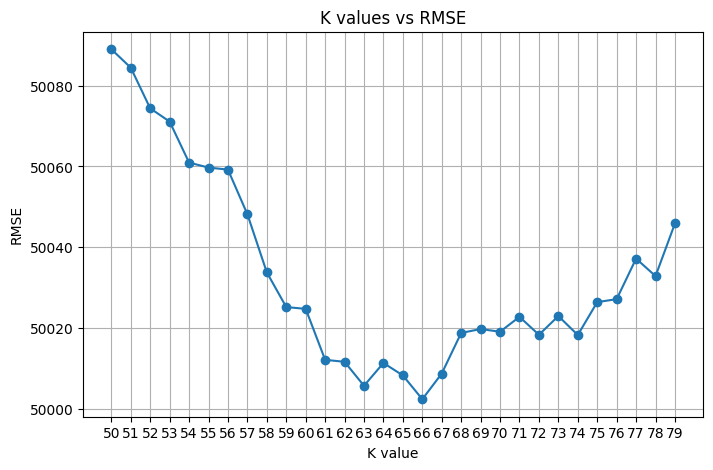

In [41]:
plt.figure(figsize = (8,5))
plt.plot(k_values, rmse_values, marker = 'o')
plt.xlabel('K value')
plt.ylabel("RMSE")
plt.title("K values vs RMSE")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [46]:
import numpy as np

# np.argmin(() --> returns the position of the smallest rmse in the list
best_index = np.argmin(rmse_values)
best_index

np.int64(16)

In [43]:
best_k = list(k_values)[best_index]
best_k

66

In [44]:
best_rmse = rmse_values[best_index]
best_rmse

np.float64(50002.362295107996)

In [45]:
print("Best K Value:", best_k)
print("Minimum RMSE:", round(best_rmse, 3))

Best K Value: 66
Minimum RMSE: 50002.362
